<a href="https://colab.research.google.com/github/piihutanoch/pet-breed-classifier/blob/main/notebooks/02_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json, sys, time
import torch

Mounted at /content/drive


In [3]:
project_dir= Path("/content/drive/MyDrive/pet-breed-classifier")
artifacts_dir= project_dir/"artifacts"
src_dir= project_dir/"src"            # reusable .py files live here
data_dir= Path("/content/data")

artifacts_dir.mkdir(parents=True, exist_ok=True)
src_dir.mkdir(parents=True, exist_ok= True)
data_dir.mkdir(parents=True, exist_ok= True)

In [4]:
seed= 42
torch.manual_seed(seed)

# Select GPU when CUDA is available
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [5]:
!wget -q --show-progress https://s3.amazonaws.com/fast-ai-imageclas/oxford-iiit-pet.tgz -O /content/pets.tgz
!tar -xzf /content/pets.tgz -C /content/data
!ls /content/data/oxford-iiit-pet

/content/pets.tgz   100%[===================>] 774.10M  17.3MB/s    in 47s     
annotations  images


In [6]:
# Load the previously saved training and validation indices
with open(artifacts_dir/"splits.json") as f:
    splits= json.load(f)

train_idx= splits["train"]
val_idx= splits["val"]

# Load the numerical index-to-breed mapping
with open(artifacts_dir/"classes.json") as f:
    idx_to_class= json.load(f)

print("train:", len(train_idx), "val:", len(val_idx))   # 3128, 552
print("class 0:", idx_to_class["0"])                     # JSON keys are strings

train: 3128 val: 552
class 0: Abyssinian


### Loading Saved Dataset Information

The training and validation indices are loaded from `splits.json`, while the class mapping is retrieved from `classes.json`.

The `splits.json` file stores:
- `seed`: Random seed (42) used during the original split.
- `train`: Indices of the 3,128 training samples.
- `val`: Indices of the 552 validation samples.

This allows the exact same dataset split to be reused across notebooks and experiments.

The `classes.json` file maps numerical class indices (0–36) to their corresponding breed names. Since JSON stores dictionary keys as strings, indices are accessed using string keys (e.g., `"0"`).

In [7]:
%%writefile /content/drive/MyDrive/pet-breed-classifier/src/data.py
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet
from torch.utils.data import Subset, DataLoader

# ImageNet's per-channel (R, G, B) mean and std: the stats the pretrained model was trained with
IMAGENET_MEAN= [0.485, 0.456, 0.406]
IMAGENET_STD= [0.229, 0.224, 0.225]


def get_eval_transform():
    """Preprocessing for val, test and the app: exactly what the pretrained model expects."""
    return transforms.Compose([
        transforms.Resize(256),             # shorter side -> 256, keeps aspect ratio
        transforms.CenterCrop(224),         # central 224x224 square
        transforms.ToTensor(),              # PIL -> tensor (3, 224, 224), values 0..1
        transforms.Normalize(mean= IMAGENET_MEAN, std= IMAGENET_STD),   # (x - mean) / std
    ])


def get_train_transform():
    return get_eval_transform()


def get_loaders(data_dir, train_idx, val_idx, batch_size=32):
    # Two dataset objects over the same files, each with its own transform
    train_base= OxfordIIITPet(root=data_dir, split="trainval",
                               target_types="category", transform=get_train_transform())
    val_base= OxfordIIITPet(root=data_dir, split="trainval",
                             target_types="category", transform=get_eval_transform())

    # Keep only the positions from Day 1's saved split
    train_ds= Subset(train_base, train_idx)
    val_ds= Subset(val_base, val_idx)

    train_loader= DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader= DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2)  # order doesn't matter for scoring
    return train_loader, val_loader

Overwriting /content/drive/MyDrive/pet-breed-classifier/src/data.py


### Creating a Reusable Data Loading Module

The preprocessing and data-loading functions are moved into `src/data.py` to make them reusable across notebooks and the application.

The module defines ImageNet mean and standard deviation values for normalising RGB images, along with separate functions for training and evaluation transformations.

Images are resized so that their shorter side measures 256 pixels, followed by a 224 × 224 centre crop. They are then converted into tensors and normalised using ImageNet statistics.

The `get_loaders()` function creates separate training and validation dataset objects using the previously saved indices. Both are wrapped in DataLoaders with a batch size of 32. Shuffling is enabled for training and disabled for validation.

Currently, both transformation pipelines are identical, with no additional data augmentation. This provides a consistent baseline for evaluating the model.

In [8]:
# Make the project directory available for imports
import importlib
sys.path.append(str(project_dir))

# Import and reload the custom data module
import src.data
importlib.reload(src.data)
from src.data import get_loaders

# Create training and validation DataLoaders
train_loader, val_loader= get_loaders(
    data_dir, train_idx, val_idx, batch_size=32
)

In [9]:
# Retrieve a batch to verify preprocessing
images, labels= next(iter(train_loader))

print("Batch shape:", images.shape)
print("Min:", round(images.min().item(), 2))
print("Max:", round(images.max().item(), 2))
print("Mean:", round(images.mean().item(), 2))

# Inspect the official EfficientNet-B0 preprocessing
from torchvision.models import EfficientNet_B0_Weights

print(EfficientNet_B0_Weights.DEFAULT.transforms())


Batch shape: torch.Size([32, 3, 224, 224])
Min: -2.12
Max: 2.64
Mean: 0.06
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)


### Verifying the Data Loading Pipeline

The custom data module is imported and reloaded to ensure that its latest changes are used. The `get_loaders()` function creates the training and validation DataLoaders using the previously saved dataset splits.

A batch is retrieved to verify its dimensions and normalised pixel value range. The preprocessing configuration is also compared with the official EfficientNet-B0 transformations to check compatibility with the pretrained model.

In [10]:
%%writefile /content/drive/MyDrive/pet-breed-classifier/src/model.py
import torch.nn as nn
from torchvision import models


def build_model(name="efficientnet_b0", num_classes=37, freeze=True):
    if name == "efficientnet_b0":
        # Download EfficientNet-B0 with its ImageNet-pretrained weights
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

        # 1) Freeze every pretrained weight (used, but never updated)
        if freeze:
            for param in model.parameters():
                param.requires_grad = False

        # 2) Replace the 1000-class head with a new 37-class one.
        #    A new layer has requires_grad=True by default, so it trains.
        in_features = model.classifier[1].in_features # Access the Linear layer (index 1) and retrieve its input features (1280) [0] is dropoutlayer
        model.classifier[1] = nn.Linear(in_features, num_classes) # 1280, 37
    else:
        raise ValueError(f"Unknown model name: {name}")   # ResNet-50 added Wednesday

    return model

Overwriting /content/drive/MyDrive/pet-breed-classifier/src/model.py


### Building the Model Architecture

EfficientNet-B0 is loaded with ImageNet-pretrained weights using transfer learning. Its pretrained convolutional layers act as a feature extractor, identifying useful visual patterns such as edges, textures and shapes.

When `freeze=True`, the pretrained weights are frozen using `requires_grad=False`, preventing them from being updated during training.

The original classification head, designed for 1,000 ImageNet classes, is replaced with a new Linear layer. `model.classifier[1]` accesses the original Linear layer (index 1), and its 1,280 input features are mapped to 37 pet breed classes.

The new classification layer remains trainable, allowing the model to learn breed classification while retaining the pretrained visual features.

In [11]:
# Import and reload the custom model module
import src.model
importlib.reload(src.model)
from src.model import build_model

# Create EfficientNet-B0 with frozen pretrained layers
model= build_model("efficientnet_b0", num_classes=37, freeze=True)

# Move the model to the selected device (GPU/CPU)
model= model.to(device)

# Inspect the modified classification head
print(model.classifier)

# Count all model parameters, including frozen ones
total= sum(p.numel() for p in model.parameters())

# Count only parameters that will be updated during training
trainable= sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"total params: {total:,}")
print(f"trainable params: {trainable:,}") #(1280*37)+37 = 47,397


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 128MB/s]


Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=37, bias=True)
)
total params: 4,054,945
trainable params: 47,397


### Model Initialisation and Parameter Inspection

The EfficientNet-B0 model is initialised with pretrained ImageNet weights and its classification layer is replaced to predict 37 pet breeds. The model is then moved to the selected device (GPU or CPU).

Parameter inspection helps verify the effect of freezing the pretrained layers. Only the newly added classification layer remains trainable, while the pretrained feature extractor retains its learned weights. This reduces the number of parameters updated during training and makes the model more computationally efficient.

In [1]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):
    model.train()  # Enable training behaviour (e.g. dropout)
    total_loss, correct, count = 0.0, 0, 0

    for images, labels in loader:
        # Move the batch to the same device as the model
        images= images.to(device)
        labels= labels.to(device)

        # Forward pass: generate logits for all 37 classes
        outputs= model(images)
        loss= loss_fn(outputs, labels)

        # Backpropagation and weight update
        optimizer.zero_grad()  # Clear gradients from the previous batch
        loss.backward()        # Calculate gradients for trainable parameters
        optimizer.step()       # Update trainable weights

        # Accumulate loss and correct predictions across batches
        batch_size= images.size(0)
        total_loss+= loss.item() * batch_size  # Convert batch mean loss to total
        preds= outputs.argmax(dim=1)           # Select the highest-scoring class
        correct+= (preds== labels).sum().item()
        count+= batch_size

    return total_loss/count, correct/count

In [15]:
def evaluate(model, loader, loss_fn, device):
    model.eval()  # Disable training-specific behaviour (e.g. dropout)
    total_loss, correct, count = 0.0, 0, 0

    # Disable gradient tracking since no weight updates are needed
    with torch.no_grad():
        for images, labels in loader:
            images= images.to(device)
            labels= labels.to(device)

            # Generate predictions and calculate loss
            outputs= model(images)
            loss= loss_fn(outputs, labels)

            # Accumulate loss and accuracy across batches
            batch_size= images.size(0)
            total_loss+= loss.item()*batch_size
            preds= outputs.argmax(dim=1)
            correct+= (preds==labels).sum().item()
            count+= batch_size

    return total_loss / count, correct / count

In [17]:
import torch.nn as nn

loss_fn= nn.CrossEntropyLoss()

# Record the model's initial validation performance before training
val_loss0, val_acc0= evaluate(model, val_loader, loss_fn, device)

print(f"Before training -> val loss: {val_loss0:.2f}, val acc: {val_acc0:.3f}")

Before training -> val loss: 3.64, val acc: 0.014


### Training and Evaluation Functions

The training function processes the dataset in batches. For each batch, the model generates predictions through forward propagation, and CrossEntropyLoss measures the prediction error. Backpropagation calculates gradients, which the optimizer uses to update the trainable parameters.

Loss and accuracy are accumulated across batches to calculate the overall training metrics for an epoch.

The evaluation function measures performance on the validation set without updating model weights. Evaluation mode disables training-specific behaviour such as dropout, while torch.no_grad() prevents unnecessary gradient calculations, reducing memory usage and computation.

An initial evaluation is performed before training to establish a baseline for comparison with subsequent results.

In [19]:
optimizer= torch.optim.Adam(
    model.classifier.parameters(),  # Update only the trainable classifier parameters
    lr=1e-3
)

num_epochs= 5

# Store metrics from each epoch for later analysis and plotting
history= {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "epoch_time": []
}

best_val_acc= 0.0
ckpt_path= artifacts_dir/"baseline_b0.pt"

for epoch in range(1, num_epochs+1):
    start= time.time()

    # Train on the training set, then evaluate on the validation set
    train_loss, train_acc= train_one_epoch(
        model, train_loader, loss_fn, optimizer, device
    )
    val_loss, val_acc= evaluate(
        model, val_loader, loss_fn, device
    )

    epoch_time= time.time()-start

    # Record metrics for this epoch
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["epoch_time"].append(epoch_time)

    # Display training progress
    print(f"Epoch {epoch}/{num_epochs} | "
          f"train loss {train_loss:.3f} acc {train_acc:.3f} | "
          f"val loss {val_loss:.3f} acc {val_acc:.3f} | {epoch_time:.0f}s")

    # Save the model whenever validation accuracy improves
    if val_acc > best_val_acc:
        best_val_acc= val_acc
        torch.save(model.state_dict(), ckpt_path)
        print("new best, checkpoint saved")

print("\nBest val accuracy:", round(best_val_acc, 4))

# Save training history as JSON for later analysis
with open(artifacts_dir/"baseline_history.json", "w") as f:
    json.dump(history, f)


Epoch 1/5 | train loss 0.366 acc 0.925 | val loss 0.465 acc 0.871 | 20s
new best, checkpoint saved
Epoch 2/5 | train loss 0.285 acc 0.947 | val loss 0.426 acc 0.884 | 22s
new best, checkpoint saved
Epoch 3/5 | train loss 0.266 acc 0.946 | val loss 0.428 acc 0.880 | 20s
Epoch 4/5 | train loss 0.227 acc 0.958 | val loss 0.412 acc 0.884 | 20s
Epoch 5/5 | train loss 0.210 acc 0.960 | val loss 0.401 acc 0.871 | 22s

Best val accuracy: 0.8841


### Baseline Model Training

The EfficientNet-B0 model is trained for five epochs using the Adam optimizer with a learning rate of 0.001. Only the classifier parameters are updated, while the pretrained feature extractor remains frozen.

After each epoch, the model is evaluated on the validation set. Training and validation loss, accuracy, and epoch duration are recorded to track performance.

A checkpoint containing the model parameters is saved whenever validation accuracy improves, ensuring that the best-performing model is retained. The training history is also saved as a JSON file for subsequent analysis and visualisation.

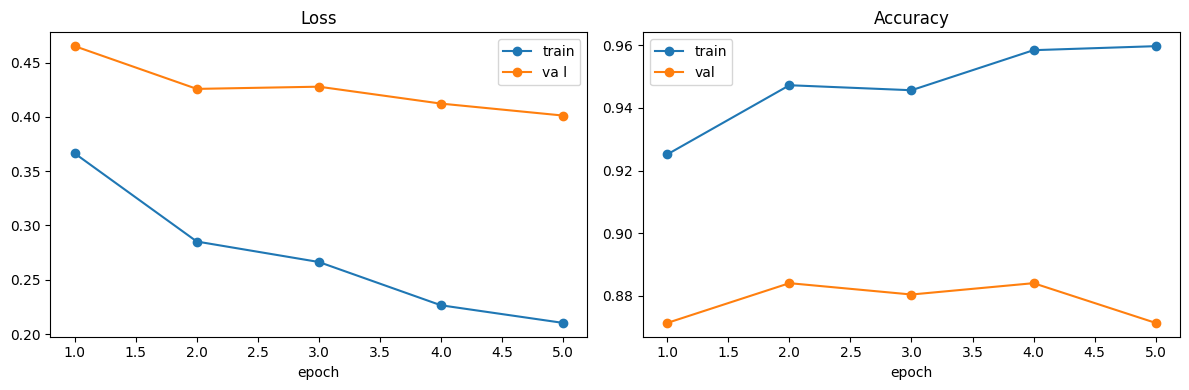

In [20]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs, history["train_loss"], marker="o", label="train")
ax1.plot(epochs, history["val_loss"], marker="o", label="va l")
ax1.set_title("Loss"); ax1.set_xlabel("epoch"); ax1.legend()

ax2.plot(epochs, history["train_acc"], marker="o", label="train")
ax2.plot(epochs, history["val_acc"], marker="o", label="val")
ax2.set_title("Accuracy"); ax2.set_xlabel("epoch"); ax2.legend()

plt.tight_layout()
plt.savefig(artifacts_dir/"baseline_curves.png", dpi=120)   # dpi is dots per inch
plt.show()

### Baseline Training Results

The training loss decreased consistently from approximately 0.37 to 0.21, while training accuracy improved from 92.5% to 96.0%, indicating that the model learned the training data effectively.

However, validation accuracy fluctuated around 87–88% and ended at approximately 87.1%. Although validation loss decreased from 0.47 to 0.40, the widening gap between training and validation performance suggests potential overfitting.

The model achieved its highest validation accuracy of approximately 88.4% during epochs 2 and 4. The best checkpoint was retained based on validation accuracy rather than the final epoch's performance.

These results provide a baseline for comparison with subsequent model improvements.

In [21]:
# Recreate the same model architecture before loading its saved parameters
best_model= build_model(
    "efficientnet_b0", num_classes=37, freeze=True
).to(device)

# Load the best checkpoint into the recreated model
best_model.load_state_dict(
    torch.load(ckpt_path, map_location=device)
)

# Evaluate the reloaded model; only validation accuracy is needed
_, reloaded_acc = evaluate(best_model, val_loader, loss_fn, device)

# Compare accuracy before and after checkpoint reloading
print(
    "best during training:", round(best_val_acc, 4),
    "reloaded:", round(reloaded_acc, 4)
)

# Verify that the reloaded model reproduces the original performance
assert abs(reloaded_acc - best_val_acc) < 0.002


best during training: 0.8841 reloaded: 0.8841


### Checkpoint Verification

The best-performing model checkpoint is reloaded into a newly initialised EfficientNet-B0 architecture. Its validation accuracy is compared with the best validation accuracy recorded during training.

An assertion checks that the difference between the two values is within a small tolerance. This verifies that the saved model parameters can be restored correctly and reproduce the expected performance.